# Задание 2. LDA

Данные и ноутбуки лежат в [репозитории MachineLearning](https://github.com/DEMest/MachineLearning); задание 1 — в [MachineLearning_Colab.ipynb](https://github.com/DEMest/MachineLearning/blob/main/MachineLearning_Colab.ipynb). Датасет для задания 2 генерируется прямо здесь функцией `make_blobs`, внешние файлы не нужны.

**Как использовать:** в Google Colab выберите `Среда выполнения → Выполнить все`. Полный прогон занимает около 5–10 минут: дольше всего идёт кросс-валидация в пункте [9] на датасете из 10 млн строк. Памяти нужно около 2 ГБ, бесплатной среды Colab хватает.

**Договорённости.** Повторяем объекты класса 0. В пунктах [4]–[9] используем пару классов 0 и 1 и пару признаков `x1`, `x4`. Решающая функция линейная: `f(x) = w₁·x1 + w₄·x4 + b`; при `f(x) > 0` объект относится к классу 1, при `f(x) < 0` — к классу 0.

## Подготовка среды

Устанавливаем только библиотеки, которых может не быть в среде выполнения.

In [1]:
import importlib.util
import subprocess
import sys
required = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'seaborn': 'seaborn', 'scikit-learn': 'sklearn', 'scipy': 'scipy',
}
missing = [package for package, module in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
print('Библиотеки готовы:', ', '.join(required))

Библиотеки готовы: numpy, pandas, matplotlib, seaborn, scikit-learn, scipy


Импорты, параметры и вспомогательные функции для таблиц и графиков.

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from sklearn.datasets import make_blobs
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import auc, average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC

RANDOM_STATE = 42
N_PER_CLASS = 1000
CLUSTER_STD = 2.5
FEATURES = ["x1", "x2", "x3", "x4"]
CLASSES = [0, 1, 2]
REPEATS = {
    "df1": 1, "df2": 2, "df5": 5, "df10": 10, "df20": 20,
    "df50": 50, "df100": 100, "df1000": 1000, "df10k": 10_000,
}
REPEATED = 0          # объекты этого класса повторяются в df2 … df10k
OTHER = 1             # второй класс выбранной пары
PAIR = ["x1", "x4"]   # выбранная пара признаков

CLASS_COLORS = {0: "#0284c7", 1: "#d97706", 2: "#7c3aed"}
CLASS_MARKERS = {0: "o", 1: "^", 2: "s"}
ZONE_COLORS = {0: "#e0f2fe", 1: "#fef3c7"}
K_COLORS = dict(zip(REPEATS, plt.cm.Purples(np.linspace(0.35, 1.0, len(REPEATS)))))

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})


def show(frame, title=None, fmt="{:.4g}"):
    """Показать таблицу с компактным форматом чисел."""
    if title:
        display(Markdown(f"**{title}**"))
    with pd.option_context("display.float_format", fmt.format,
                           "display.max_columns", 50, "display.width", 250):
        display(frame)


def pair_arrays(df):
    """Строки выбранной пары классов: признаки x1, x4, класс и номер исходного объекта."""
    part = df.loc[df["target"].isin([REPEATED, OTHER]), [*PAIR, "target", "obj_id"]]
    return part[PAIR].to_numpy(), part["target"].to_numpy(), part["obj_id"].to_numpy()


def draw_regions(ax, score_fn, title):
    """Зоны классов, граница f(x) = 0 и объекты пары классов из df1."""
    (x_lo, x_hi), (y_lo, y_hi) = LIMITS
    gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 300), np.linspace(y_lo, y_hi, 300))
    score = score_fn(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, (score > 0).astype(int), levels=[-0.5, 0.5, 1.5],
                colors=[ZONE_COLORS[REPEATED], ZONE_COLORS[OTHER]])
    has_boundary = score.min() < 0 < score.max()
    if has_boundary:
        ax.contour(gx, gy, score, levels=[0], colors="#1f2937", linewidths=1.8)
    for cls in (REPEATED, OTHER):
        part = X1[y1 == cls]
        ax.scatter(part[:, 0], part[:, 1], s=9, c=CLASS_COLORS[cls], marker=CLASS_MARKERS[cls],
                   alpha=0.55, linewidths=0, label=f"класс {cls}")
    ax.set(xlim=(x_lo, x_hi), ylim=(y_lo, y_hi), xlabel="x1", ylabel="x4",
           title=title if has_boundary else f"{title}\nграница вне области графика")


def draw_boundaries(ax, models, title):
    """Все границы f(x) = 0 на одном графике поверх объектов df1."""
    for cls in (REPEATED, OTHER):
        part = X1[y1 == cls]
        ax.scatter(part[:, 0], part[:, 1], s=8, c=CLASS_COLORS[cls], marker=CLASS_MARKERS[cls],
                   alpha=0.25, linewidths=0)
    ax.plot(*np.c_[MU[REPEATED], MU[OTHER]], color="#6b7280", linewidth=1.2, linestyle="--")
    for cls in (REPEATED, OTHER):
        ax.scatter(*MU[cls], s=180, c=CLASS_COLORS[cls], marker="X", edgecolors="white",
                   linewidths=1.2, zorder=5, label=f"центр класса {cls}")
    xs = np.linspace(*LIMITS[0], 50)
    for name, model in models.items():
        (w1, w4), b = model.coef_[0], model.intercept_[0]
        ax.plot(xs, -(b + w1 * xs) / w4, color=K_COLORS[name], linewidth=2, label=f"{name} (k = {REPEATS[name]})")
    ax.set(xlim=LIMITS[0], ylim=LIMITS[1], xlabel="x1", ylabel="x4", title=title)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))

## [1] Генерация датасета df1

`make_blobs` с `random_state=42` создаёт три гауссовых облака по 1000 объектов в четырёхмерном пространстве. Все четыре признака непрерывные (`float64`). Разброс внутри класса одинаков по всем осям: `cluster_std = 2.5`. Он подобран так, чтобы выбранные далее классы 0 и 1 частично перекрывались: при полностью разделимых классах ROC- и PR-кривые были бы тривиальными.

Столбец `obj_id` — номер исходного объекта. Копии в df2 … df10k сохраняют его; он понадобится в пункте [9].

In [3]:
X, y, true_centers = make_blobs(
    n_samples=[N_PER_CLASS] * len(CLASSES), n_features=len(FEATURES),
    cluster_std=CLUSTER_STD, random_state=RANDOM_STATE, return_centers=True,
)
df1 = pd.DataFrame(X, columns=FEATURES)
df1["target"] = y
df1["obj_id"] = np.arange(len(df1))
assert len(df1) == 3 * N_PER_CLASS and df1["target"].value_counts().eq(N_PER_CLASS).all()

show(df1.head(), "Первые строки df1")
show(pd.DataFrame(true_centers, columns=FEATURES).rename_axis("Класс").reset_index(),
     "Центры классов, заданные make_blobs")

**Первые строки df1**

,x1,x2,x3,x4,target,obj_id
0,1.261,3.379,-8.042,14.36,2,0
1,3.52,4.601,-12.01,5.944,2,1
2,-2.782,-4.61,-10.61,12.85,1,2
3,-1.946,10.75,1.467,6.229,0,3
4,-5.367,11.06,4.478,2.155,0,4


**Центры классов, заданные make_blobs**

,Класс,x1,x2,x3,x4
0,0,-2.509,9.014,4.64,1.973
1,1,-6.88,-6.88,-8.838,7.324
2,2,2.022,4.161,-9.588,9.398


## [2] Ключевые характеристики, корреляции, все пары признаков

Повторяем шаги задания 1: размерность и типы, баланс классов, пропуски, описательная статистика — по всей выборке и по классам.

In [4]:
overview = pd.DataFrame([
    ("Объектов", len(df1)),
    ("Количественных признаков", len(FEATURES)),
    ("Тип признаков", ", ".join(sorted(set(df1[FEATURES].dtypes.astype(str))))),
    ("Классов", df1["target"].nunique()),
    ("Пропусков", int(df1[FEATURES].isna().sum().sum())),
    ("Повторяющихся строк", int(df1[FEATURES].duplicated().sum())),
    ("Минимум уникальных значений в признаке", int(df1[FEATURES].nunique().min())),
], columns=["Показатель", "Значение"])
show(overview, "Обзор df1")
show(df1["target"].value_counts().sort_index().rename_axis("Класс").reset_index(name="Объектов"),
     "Объектов по классам")

summary = df1[FEATURES].describe().T
summary["асимметрия"] = df1[FEATURES].skew()
summary["эксцесс"] = df1[FEATURES].kurt()
show(summary.rename_axis("Признак").reset_index(), "Описательная статистика по всей выборке")

by_class = df1.groupby("target")[FEATURES].agg(["mean", "std", "skew"])
by_class.index.name = "Класс"
show(by_class, "Среднее, стандартное отклонение и асимметрия по классам", fmt="{:.3f}")

**Обзор df1**

,Показатель,Значение
0,Объектов,3000
1,Количественных признаков,4
2,Тип признаков,float64
3,Классов,3
4,Пропусков,0
5,Повторяющихся строк,0
6,Минимум уникальных значений в признаке,3000


**Объектов по классам**

,Класс,Объектов
0,0,1000
1,1,1000
2,2,1000


**Описательная статистика по всей выборке**

,Признак,count,mean,std,min,25%,50%,75%,max,асимметрия,эксцесс
0,x1,3000,-2.414,4.39,-14.93,-5.727,-2.428,0.9701,10.47,0.005035,-0.6845
1,x2,3000,2.051,7.193,-15.88,-5.362,3.976,7.839,18.65,-0.3565,-1.142
2,x3,3000,-4.672,7.03,-19.39,-10.15,-7.659,2.933,12.52,0.5763,-1.14
3,x4,3000,6.249,3.991,-5.505,3.224,6.656,9.274,16.15,-0.2338,-0.5895


**Среднее, стандартное отклонение и асимметрия по классам**

x1                  x2                  x3                 x4             
        mean   std   skew   mean   std   skew   mean   std   skew  mean   std   skew
Класс                                                                               
0     -2.439 2.413 -0.043  9.079 2.530  0.104  4.607 2.521  0.005 2.042 2.515  0.034
1     -6.815 2.545  0.082 -7.053 2.506 -0.032 -8.941 2.537  0.056 7.292 2.571 -0.067
2      2.013 2.560 -0.124  4.128 2.430 -0.019 -9.683 2.455 -0.003 9.414 2.462 -0.048

Внутри каждого класса стандартное отклонение близко к заданным 2.5 (от 2.41 до 2.57), асимметрия — к нулю (|skew| ≤ 0.13): классы — симметричные гауссовы облака. По всей выборке разброс больше (у `x2` и `x3` стандартное отклонение около 7), а эксцесс отрицательный: это смесь трёх облаков с разными центрами, и распределение признака вместо одного пика имеет несколько.

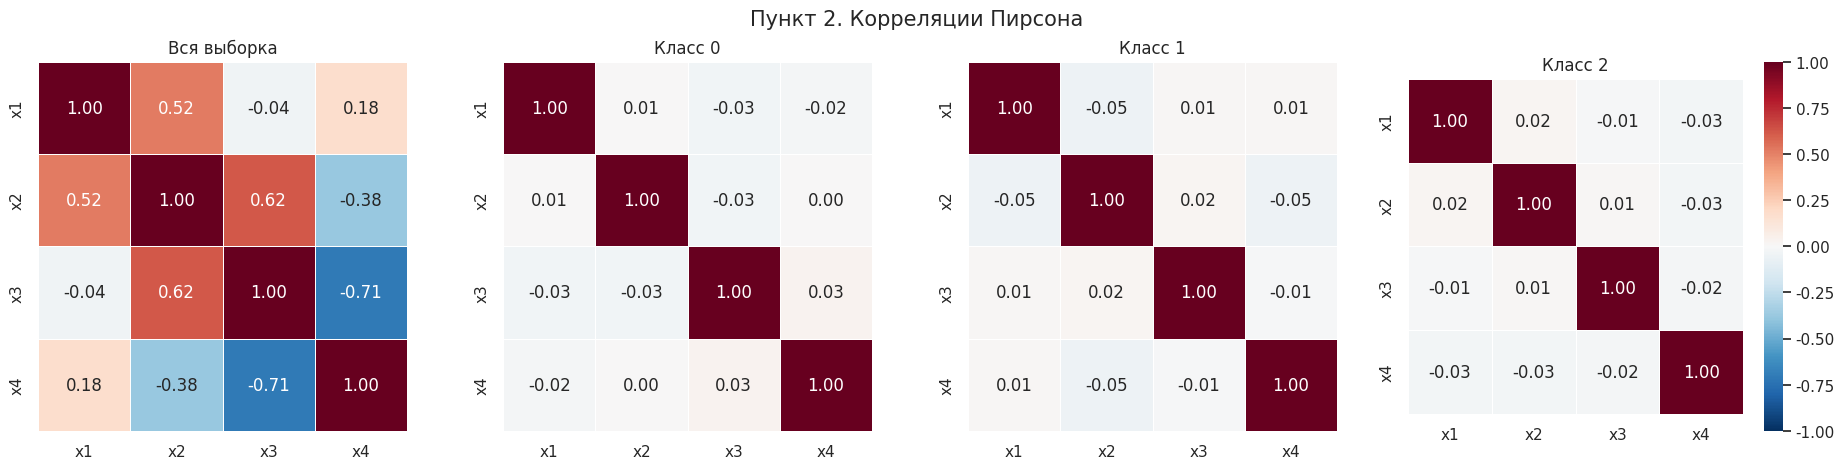

Максимальная |r| внутри классов: 0.054


**Корреляции по всей выборке**

,x1,x2,x3,x4
x1,1.000,0.516,-0.041,0.177
x2,0.516,1.000,0.617,-0.383
x3,-0.041,0.617,1.000,-0.705
x4,0.177,-0.383,-0.705,1.000


In [5]:
correlations = {"Вся выборка": df1[FEATURES].corr(method="pearson")}
for cls in CLASSES:
    correlations[f"Класс {cls}"] = df1.loc[df1["target"] == cls, FEATURES].corr(method="pearson")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, (title, matrix) in zip(axes, correlations.items()):
    sns.heatmap(matrix, ax=ax, vmin=-1, vmax=1, cmap="RdBu_r", annot=True, fmt=".2f",
                square=True, cbar=ax is axes[-1], linewidths=0.5)
    ax.set_title(title)
fig.suptitle("Пункт 2. Корреляции Пирсона", fontsize=15)
fig.tight_layout()
plt.show()

within = max(np.abs(correlations[f"Класс {c}"].to_numpy()[np.triu_indices(4, 1)]).max() for c in CLASSES)
print(f"Максимальная |r| внутри классов: {within:.3f}")
show(correlations["Вся выборка"], "Корреляции по всей выборке", fmt="{:.3f}")

Внутри классов признаки практически не коррелируют: `make_blobs` генерирует их независимо, и |r| ≤ 0.054 — это шум выборки. Заметные корреляции по всей выборке (например, r(x3, x4) = −0.705) — следствие расположения центров. У класса 0 `x3` высокий, а `x4` низкий; у классов 1 и 2 наоборот. Смесь облаков поэтому вытягивается вдоль диагонали. Это тот же эффект смешения групп, что и в задании 1.

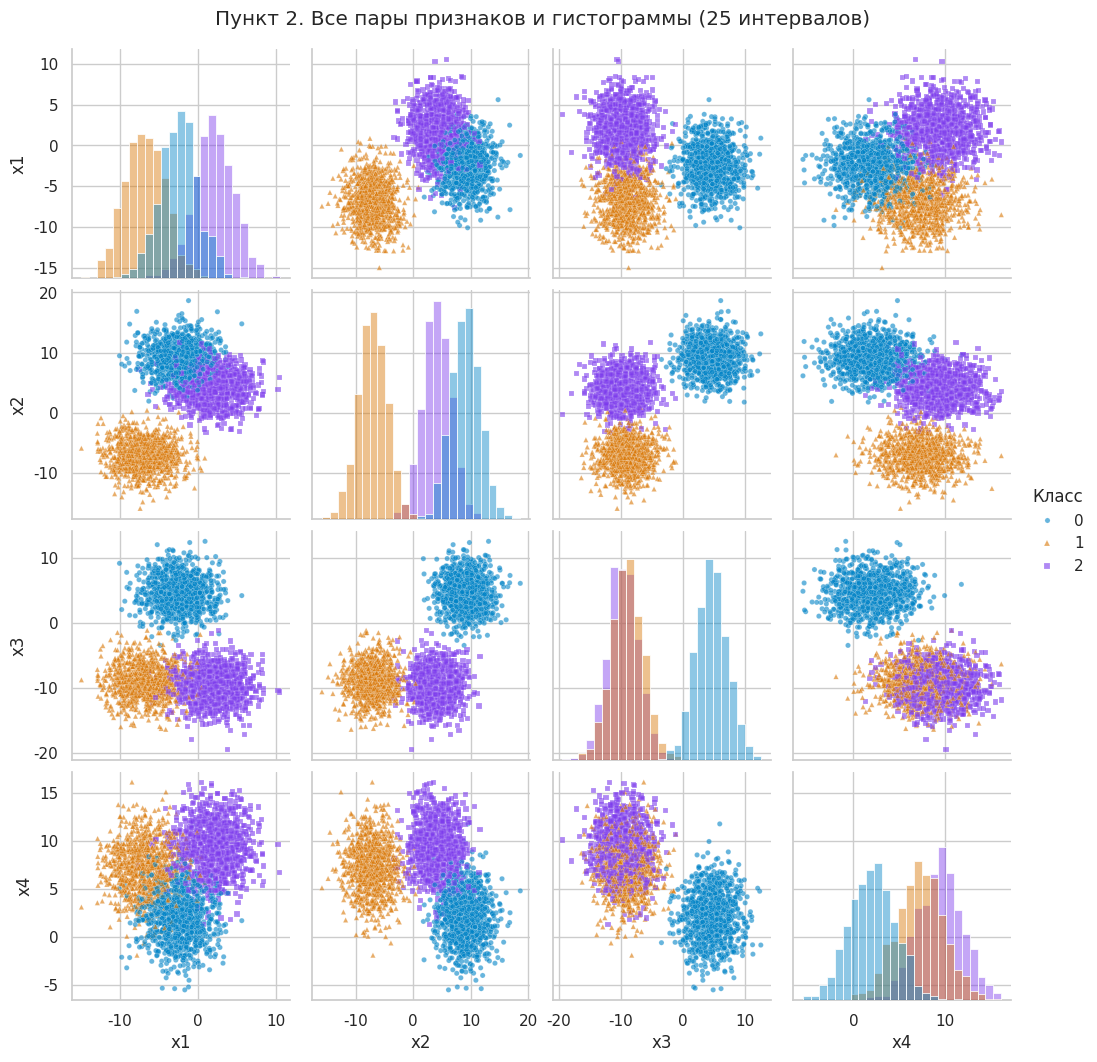

In [6]:
grid = sns.pairplot(
    df1, vars=FEATURES, hue="target", hue_order=CLASSES, palette=CLASS_COLORS,
    markers=[CLASS_MARKERS[c] for c in CLASSES], diag_kind="hist",
    diag_kws={"bins": 25, "alpha": 0.45},
    plot_kws={"alpha": 0.6, "s": 14, "edgecolor": "white", "linewidth": 0.2}, height=2.6,
)
grid._legend.set_title("Класс")
grid.fig.suptitle("Пункт 2. Все пары признаков и гистограммы (25 интервалов)", y=1.02)
plt.show()

## [3] Датасеты с повторёнными объектами

Каждый объект класса 0 повторяем k раз (k = 2, 5, 10, 20, 50, 100, 1000, 10 000); классы 1 и 2 не меняются. Новых точек повтор не добавляет: копии лежат ровно там же, где исходный объект. Меняются только доли классов и вес каждого объекта класса 0 в любых суммах по выборке. В df10k 10 002 000 строк.

In [7]:
def repeat_class(df, cls, times):
    counts = np.where(df["target"].to_numpy() == cls, times, 1)
    return df.iloc[np.repeat(np.arange(len(df)), counts)].reset_index(drop=True)


datasets = {name: repeat_class(df1, REPEATED, k) for name, k in REPEATS.items()}

class_means_1 = df1.groupby("target")[FEATURES].mean()
rows = []
for name, k in REPEATS.items():
    df = datasets[name]
    counts = df["target"].value_counts()
    assert counts[REPEATED] == k * N_PER_CLASS and counts[OTHER] == counts[2] == N_PER_CLASS
    assert np.allclose(df.groupby("target")[FEATURES].mean(), class_means_1)
    rows.append({
        "Датасет": name, "k": k, "Строк": len(df),
        "Класс 0": counts[0], "Класс 1": counts[1], "Класс 2": counts[2],
        "Доля класса 0, %": 100 * counts[0] / len(df),
        "Уникальных объектов": df["obj_id"].nunique(),
        "Память, МБ": df.memory_usage().sum() / 2**20,
    })
show(pd.DataFrame(rows), "Размеры датасетов")
print("Средние по каждому классу во всех датасетах совпадают с df1.")

**Размеры датасетов**

,Датасет,k,Строк,Класс 0,Класс 1,Класс 2,"Доля класса 0, %",Уникальных объектов,"Память, МБ"
0,df1,1,3000,1000,1000,1000,33.33,3000,0.1375
1,df2,2,4000,2000,1000,1000,50,3000,0.1832
2,df5,5,7000,5000,1000,1000,71.43,3000,0.3206
3,df10,10,12000,10000,1000,1000,83.33,3000,0.5494
4,df20,20,22000,20000,1000,1000,90.91,3000,1.007
5,df50,50,52000,50000,1000,1000,96.15,3000,2.38
6,df100,100,102000,100000,1000,1000,98.04,3000,4.669
7,df1000,1000,1002000,1000000,1000,1000,99.8,3000,45.87
8,df10k,10000,10002000,10000000,1000,1000,99.98,3000,457.9


Средние по каждому классу во всех датасетах совпадают с df1.


## [4] LDA: решающая функция, зоны и объекты

**Выбор пары.** Классы 0 (повторяемый) и 1, признаки `x1` и `x4`. На этой паре облака частично перекрываются: расстояние между центрами — около 2.7 стандартного отклонения. На остальных парах признаков классы 0 и 1 разделены почти полностью (см. матрицу пар), и сдвиг границы было бы трудно увидеть.

**Как повтор влияет на LDA.** LDA оценивает средние классов μ₀ и μ₁, общую ковариацию Σ и априорные вероятности π₀ = n₀/n, π₁ = n₁/n. Решающая функция:

`f(x) = (μ₁ − μ₀)ᵀ Σ⁻¹ x − ½ (μ₁ᵀ Σ⁻¹ μ₁ − μ₀ᵀ Σ⁻¹ μ₀) + ln(π₁/π₀)`.

Повтор класса 0 в k раз не меняет μ₀ и μ₁. Σ меняется мало: ковариации облаков одинаковы, меняется лишь вес выборочной ковариации класса 0. Зато π₁/π₀ = 1/k. Поэтому наклон границы почти не меняется, а свободный член уменьшается примерно на ln k — граница отходит к классу 1.

Модели обучаются на всех строках каждого датасета, включая 10 млн строк df10k. Решатель `lsqr` работает через ковариационные матрицы и тратит на df10k около секунды. На графиках точек столько же, сколько в df1: копии совпадают с исходными объектами.

In [8]:
pair_data = {name: pair_arrays(df) for name, df in datasets.items()}
X1, y1, ids1 = pair_data["df1"]
MU = {cls: X1[y1 == cls].mean(axis=0) for cls in (REPEATED, OTHER)}
LIMITS = [(X1[:, j].min() - 0.05 * np.ptp(X1[:, j]), X1[:, j].max() + 0.05 * np.ptp(X1[:, j])) for j in range(2)]
pooled_std = np.sqrt(np.mean([X1[y1 == c].var(axis=0, ddof=1).mean() for c in (REPEATED, OTHER)]))
print(f"Расстояние между центрами классов 0 и 1 на (x1, x4): "
      f"{np.linalg.norm(MU[OTHER] - MU[REPEATED]) / pooled_std:.2f} стандартного отклонения")

lda_models, rows = {}, []
for name, k in REPEATS.items():
    X, y, _ = pair_data[name]
    start = time.perf_counter()
    model = LinearDiscriminantAnalysis(solver="lsqr").fit(X, y)
    seconds = time.perf_counter() - start
    lda_models[name] = model
    pred = model.predict(X)
    (w1, w4), b = model.coef_[0], model.intercept_[0]
    rows.append({
        "Датасет": name, "k": k, "Строк в паре": len(y), "w₁ (x1)": w1, "w₄ (x4)": w4, "b": b,
        "π₀": model.priors_[0], "Recall класса 0": np.mean(pred[y == 0] == 0),
        "Recall класса 1": np.mean(pred[y == 1] == 1), "Accuracy": np.mean(pred == y),
        "Обучение, с": seconds,
    })
lda_table = pd.DataFrame(rows)
lda_table.insert(6, "b − b(df1)", lda_table["b"] - lda_table.loc[0, "b"])
lda_table.insert(7, "−ln k", -np.log(lda_table["k"]))
show(lda_table, "LDA: f(x) = w₁·x1 + w₄·x4 + b; качество на всех строках самого датасета")

Расстояние между центрами классов 0 и 1 на (x1, x4): 2.72 стандартного отклонения


**LDA: f(x) = w₁·x1 + w₄·x4 + b; качество на всех строках самого датасета**

,Датасет,k,Строк в паре,w₁ (x1),w₄ (x4),b,b − b(df1),−ln k,π₀,Recall класса 0,Recall класса 1,Accuracy,"Обучение, с"
0,df1,1,2000,-0.7097,0.8104,-7.066,0,-0,0.5,0.914,0.918,0.916,0.006936
1,df2,2,3000,-0.7171,0.812,-7.8,-0.7348,-0.6931,0.6667,0.946,0.864,0.9187,0.0008425
2,df5,5,6000,-0.7248,0.8134,-8.759,-1.694,-1.609,0.8333,0.98,0.772,0.9453,0.0006669
3,df10,10,11000,-0.7284,0.814,-9.472,-2.406,-2.303,0.9091,0.985,0.688,0.958,0.0009708
4,df20,20,21000,-0.7305,0.8144,-10.18,-3.111,-2.996,0.9524,0.992,0.608,0.9737,0.001521
5,df50,50,51000,-0.7318,0.8146,-11.1,-4.034,-3.912,0.9804,0.997,0.478,0.9868,0.003416
6,df100,100,101000,-0.7323,0.8147,-11.8,-4.73,-4.605,0.9901,1,0.384,0.9939,0.006316
7,df1000,1000,1001000,-0.7328,0.8148,-14.1,-7.035,-6.908,0.999,1,0.134,0.9991,0.06764
8,df10k,10000,10001000,-0.7328,0.8148,-16.4,-9.338,-9.21,0.9999,1,0.017,0.9999,0.6714


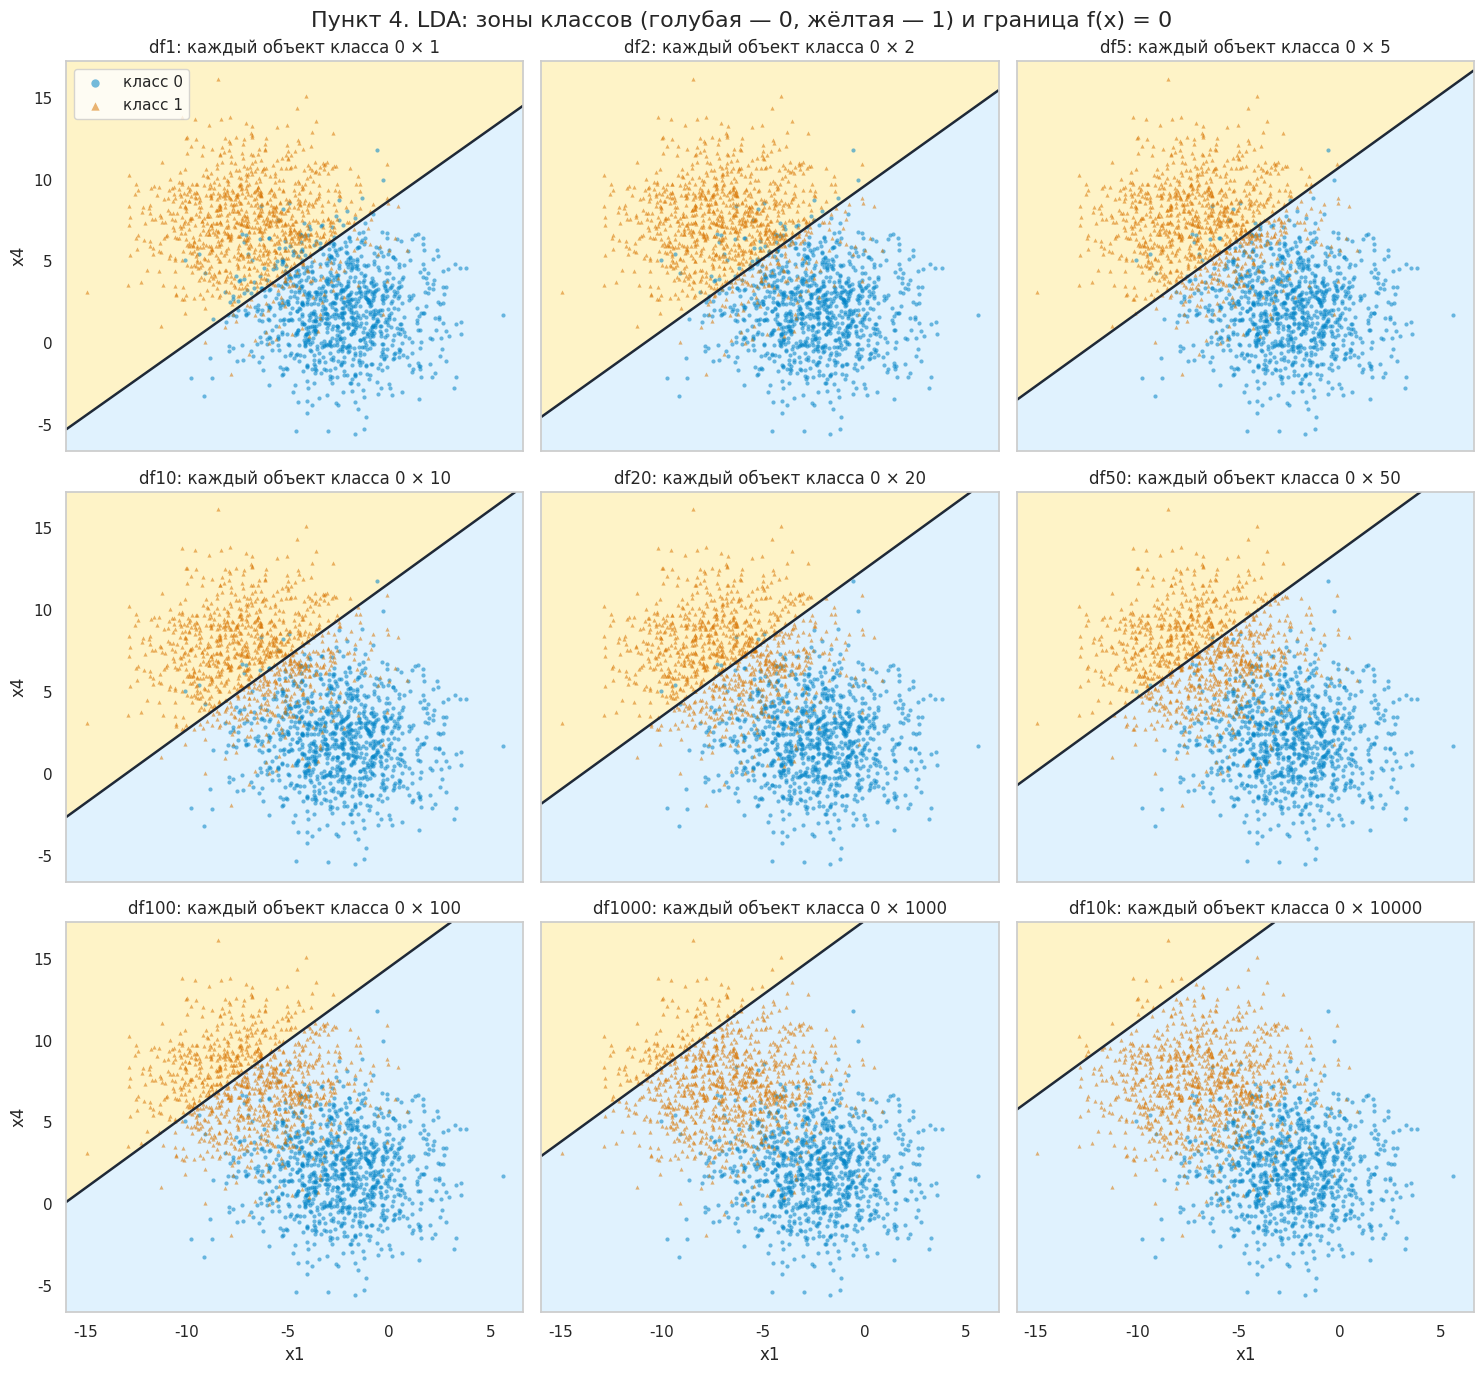

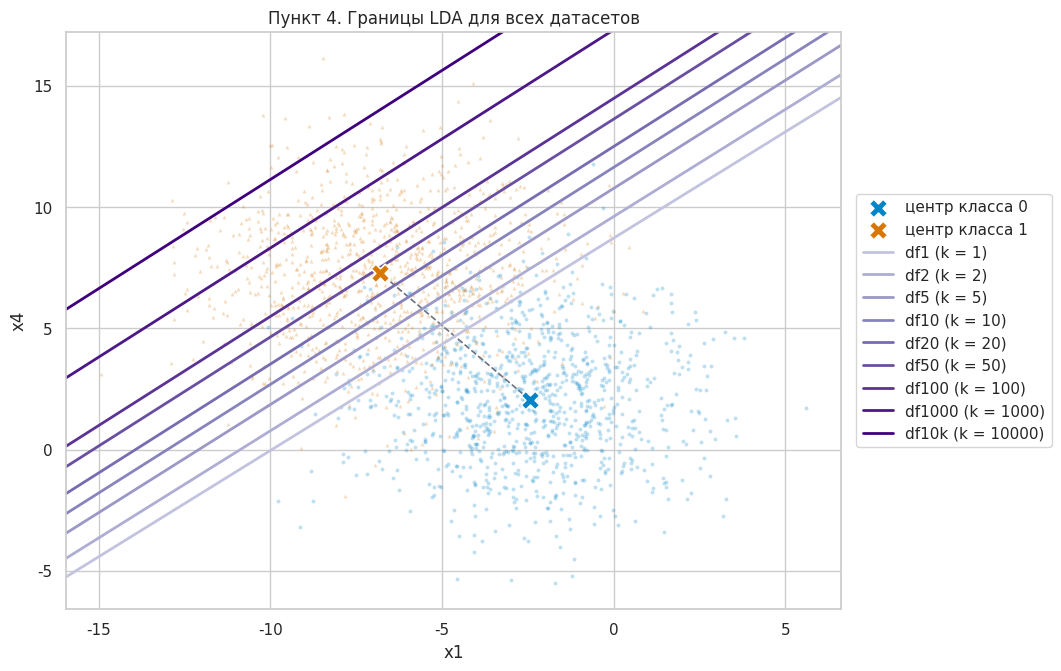

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 14), sharex=True, sharey=True)
for ax, (name, k) in zip(axes.flat, REPEATS.items()):
    draw_regions(ax, lda_models[name].decision_function, f"{name}: каждый объект класса 0 × {k}")
    ax.label_outer()
axes[0, 0].legend(loc="upper left", markerscale=2)
fig.suptitle("Пункт 4. LDA: зоны классов (голубая — 0, жёлтая — 1) и граница f(x) = 0", fontsize=16)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7.5))
draw_boundaries(ax, lda_models, "Пункт 4. Границы LDA для всех датасетов")
plt.show()

**Что видно.**

- Наклон границы почти не меняется: w₁ от −0.710 до −0.733, w₄ от 0.810 до 0.815. Граница сдвигается параллельно себе — к классу 1.
- Свободный член падает с −7.07 до −16.40. Его изменение b − b(df1) почти совпадает с −ln k: −9.34 против −9.21 для df10k. Небольшая разница — от изменения общей ковариации Σ.
- Recall класса 1 падает с 0.918 (df1) до 0.384 (df100), 0.134 (df1000) и 0.017 (df10k), а accuracy растёт с 0.916 до 0.9999. При таком дисбалансе accuracy ничего не говорит о редком классе: правило «всё — класс 0» на df10k тоже даёт 0.9999.

## [5] То же для SVM

Линейный SVM (`SVC(kernel="linear")`, C = 1, как в задании 1) минимизирует

`½‖w‖² + C · Σᵢ max(0, 1 − yᵢ·f(xᵢ))`, где yᵢ = ±1.

Если объект повторён k раз, его слагаемое входит в сумму k раз — это ровно то же, что вес k (`sample_weight`). libsvm на миллионах строк не обучается за разумное время, поэтому для всех датасетов обучаем SVM на 2000 уникальных объектах с весами. Сначала проверяем эквивалентность на df2–df20, где SVM можно обучить и на настоящих копиях.

In [10]:
def svm_weights(k):
    return np.where(y1 == REPEATED, k, 1).astype(float)


rows = []
for name in ["df2", "df5", "df10", "df20"]:
    X, y, _ = pair_data[name]
    start = time.perf_counter()
    on_copies = SVC(kernel="linear").fit(X, y)
    copies_seconds = time.perf_counter() - start
    start = time.perf_counter()
    weighted = SVC(kernel="linear").fit(X1, y1, sample_weight=svm_weights(REPEATS[name]))
    weighted_seconds = time.perf_counter() - start
    rows.append({
        "Датасет": name, "Строк в паре": len(y),
        "w на копиях": np.round(on_copies.coef_[0], 4), "w с весами": np.round(weighted.coef_[0], 4),
        "max |Δw|": np.abs(on_copies.coef_ - weighted.coef_).max(),
        "|Δb|": abs(on_copies.intercept_[0] - weighted.intercept_[0]),
        "Время на копиях, с": copies_seconds, "Время с весами, с": weighted_seconds,
    })
show(pd.DataFrame(rows), "Проверка: SVM на копиях и SVM с весами")

**Проверка: SVM на копиях и SVM с весами**

,Датасет,Строк в паре,w на копиях,w с весами,max |Δw|,|Δb|,"Время на копиях, с","Время с весами, с"
0,df2,3000,"[-0.4673, 0.5384]","[-0.4682, 0.5388]",0.0009145,0.005839,0.02623,0.01949
1,df5,6000,"[-0.4385, 0.4896]","[-0.4384, 0.4894]",0.0001656,0.001681,0.08053,0.02258
2,df10,11000,"[-0.453, 0.4711]","[-0.4529, 0.4713]",0.0001467,0.0003571,0.2204,0.03619
3,df20,21000,"[-0.3717, 0.4109]","[-0.3717, 0.4109]",1.862e-05,0.0001736,0.4965,0.1094


Коэффициенты совпадают с точностью до допуска решателя libsvm (порядка 10⁻³), значит веса можно использовать для всех датасетов.

В таблице ниже, кроме коэффициентов, есть значение целевой функции SVM. Для сравнения: константа `f(x) ≡ −1` («всё — класс 0») даёт ровно 2000 при любом k. У объектов класса 0 штраф нулевой, у каждого из 1000 объектов класса 1 он равен 2.

In [11]:
def svm_objective(model, weight):
    margin = np.where(y1 == OTHER, 1, -1) * model.decision_function(X1)
    return 0.5 * model.coef_[0] @ model.coef_[0] + np.sum(weight * np.maximum(0, 1 - margin))


svm_models, rows = {}, []
for name, k in REPEATS.items():
    weight = svm_weights(k)
    model = SVC(kernel="linear").fit(X1, y1, sample_weight=weight)
    svm_models[name] = model
    pred = model.predict(X1)
    (w1, w4), b = model.coef_[0], model.intercept_[0]
    rows.append({
        "Датасет": name, "k": k, "w₁ (x1)": w1, "w₄ (x4)": w4, "b": b,
        "‖w‖": np.linalg.norm(model.coef_[0]), "Опорных векторов": model.n_support_.sum(),
        "Целевая функция": svm_objective(model, weight),
        "Recall класса 0": np.mean(pred[y1 == 0] == 0), "Recall класса 1": np.mean(pred[y1 == 1] == 1),
        "Accuracy": np.average(pred == y1, weights=weight),
    })
svm_table = pd.DataFrame(rows)
show(svm_table, "SVM: f(x) = w₁·x1 + w₄·x4 + b; качество на датасете (с учётом копий)")

**SVM: f(x) = w₁·x1 + w₄·x4 + b; качество на датасете (с учётом копий)**

,Датасет,k,w₁ (x1),w₄ (x4),b,‖w‖,Опорных векторов,Целевая функция,Recall класса 0,Recall класса 1,Accuracy
0,df1,1,-0.4433,0.527,-4.481,0.6887,441,439,0.913,0.919,0.916
1,df2,2,-0.4682,0.5388,-5.163,0.7138,458,607.9,0.95,0.86,0.92
2,df5,5,-0.4384,0.4894,-5.304,0.657,528,878.3,0.98,0.77,0.945
3,df10,10,-0.4529,0.4713,-5.713,0.6536,605,1097,0.986,0.678,0.958
4,df20,20,-0.3717,0.4109,-5.204,0.5541,708,1344,0.992,0.592,0.973
5,df50,50,-0.2888,0.3156,-4.483,0.4278,879,1720,0.999,0.422,0.9877
6,df100,100,-0.2529,0.2868,-4.529,0.3824,982,1940,1,0.243,0.9925
7,df1000,1000,-0.001576,0.002441,-1.029,0.002905,1004,2003,1,0,0.999
8,df10k,10000,-0.001576,0.002441,-1.029,0.002905,1004,2028,1,0,0.9999


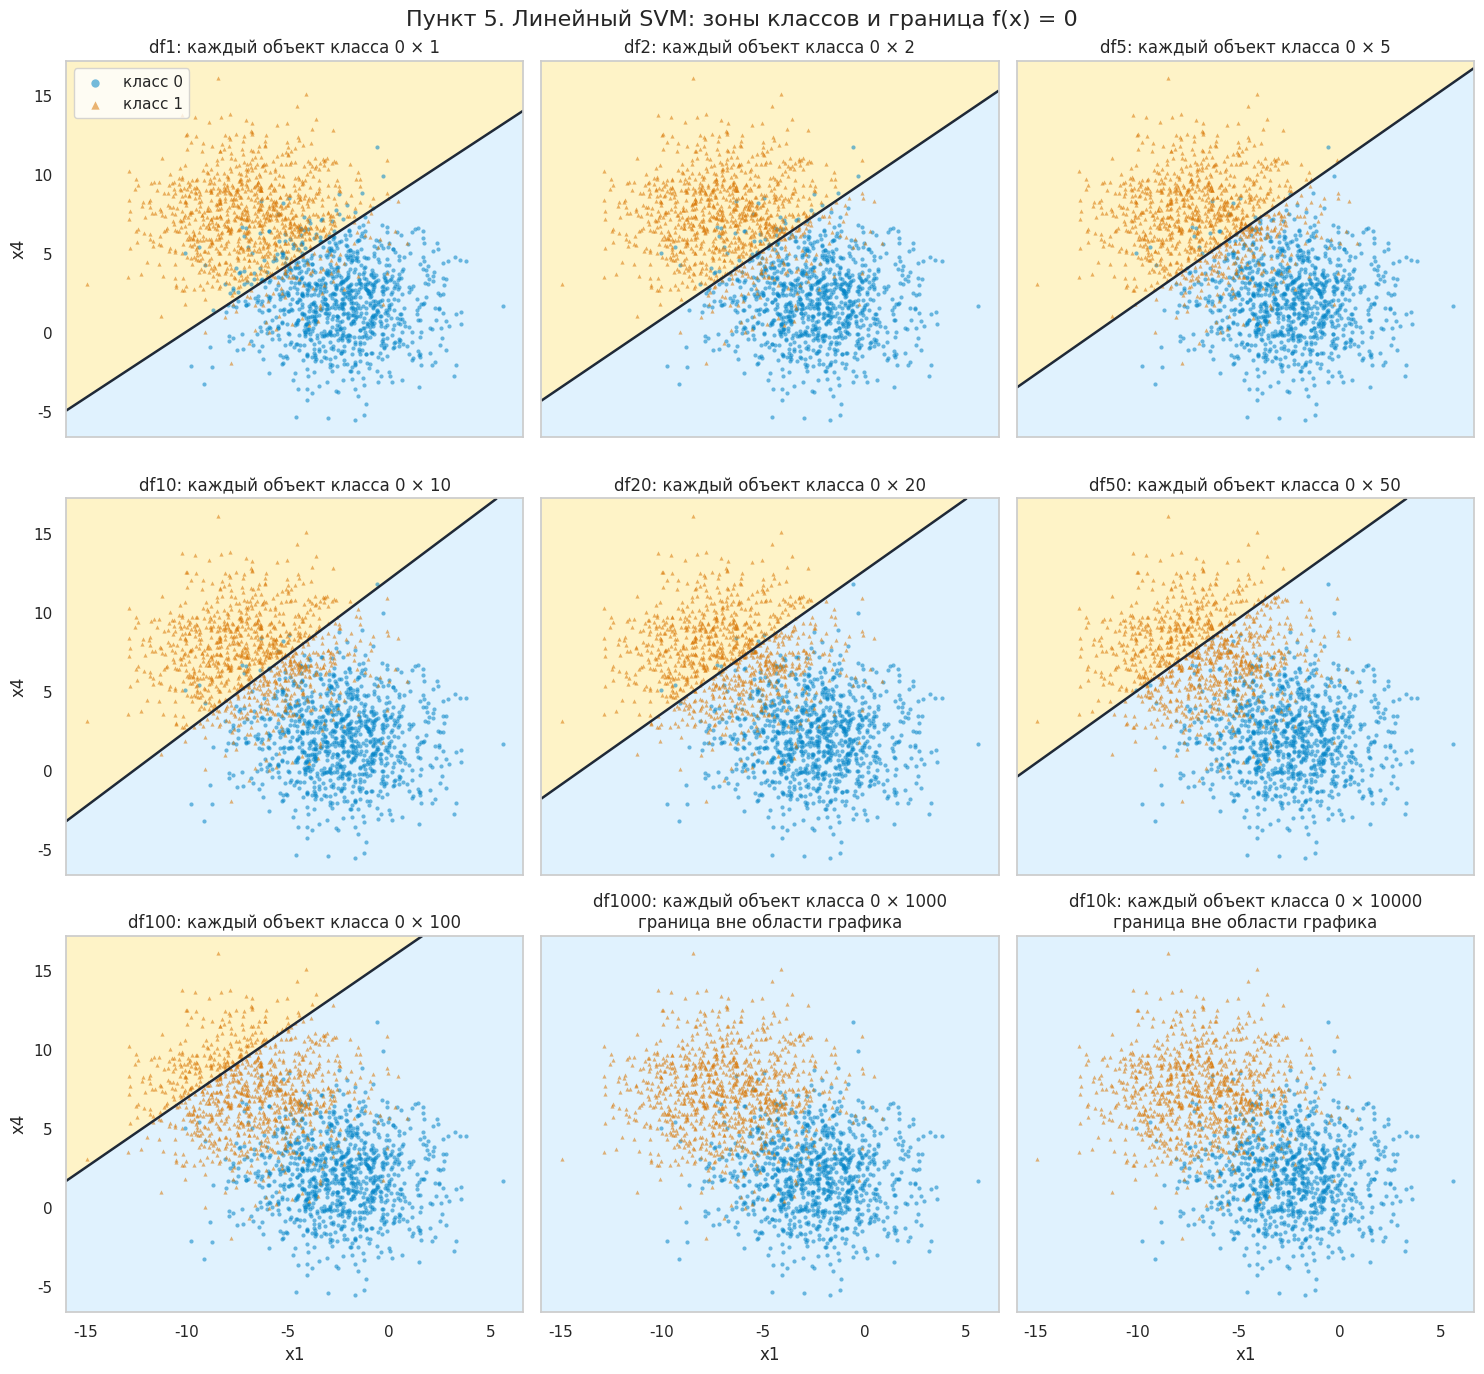

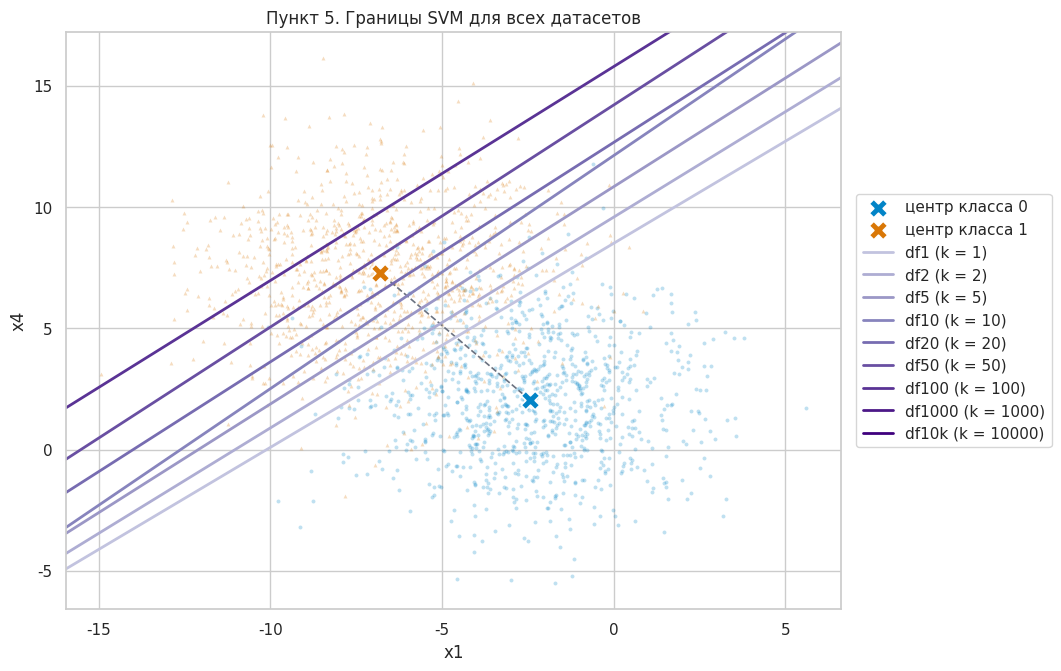

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 14), sharex=True, sharey=True)
for ax, (name, k) in zip(axes.flat, REPEATS.items()):
    draw_regions(ax, svm_models[name].decision_function, f"{name}: каждый объект класса 0 × {k}")
    ax.label_outer()
axes[0, 0].legend(loc="upper left", markerscale=2)
fig.suptitle("Пункт 5. Линейный SVM: зоны классов и граница f(x) = 0", fontsize=16)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7.5))
draw_boundaries(ax, svm_models, "Пункт 5. Границы SVM для всех датасетов")
plt.show()

**Что видно.**

- Обучение с весами совпадает с обучением на копиях: max |Δw| ≤ 9·10⁻⁴.
- При k ≤ 100 граница SVM, как и у LDA, уходит к классу 1, и уходит быстрее: recall класса 1 на df100 равен 0.243 против 0.384 у LDA. Одновременно в целом уменьшается ‖w‖ (с 0.69 на df1 до 0.38 на df100), то есть полоса зазора шириной 2/‖w‖ расширяется; в пределе ‖w‖ уходит к нулю (см. следующий пункт).
- При k = 1000 и 10 000 решение вырождается: ‖w‖ ≈ 0.003, b ≈ −1.03. Значит, f(x) ≈ −1 во всей области данных, все объекты относятся к классу 0, recall класса 1 равен 0. Граница `f(x) = 0` уходит примерно на |b|/‖w‖ ≈ 350 единиц от данных. У константы `f ≡ −1` целевая функция равна 2000 — даже меньше, чем у решения libsvm (2003 и 2028; решатель останавливается по допуску рядом с ней). Причина: любой наклон, который помогает классу 1, штрафует объекты класса 0, лежащие среди объектов класса 1, с весом k ≥ 1000 — это дороже выигрыша.
- LDA при том же дисбалансе сохраняет направление и только сдвигает границу; SVM с hinge-loss при сильном дисбалансе теряет направление совсем.

## [6] Центры масс и пересечение с решающей функцией LDA

Для каждого датасета находим три точки на плоскости (x1, x4):

- **центр отрезка** между центрами масс классов 0 и 1: (μ₀ + μ₁) / 2;
- **общий центр масс** двух выбранных классов с учётом копий. Считаем прямо по строкам датасета; он должен совпасть с (k·μ₀ + μ₁) / (k + 1);
- **пересечение** границы LDA `f(x) = 0` с прямой μ₀ → μ₁. Точки прямой: x(t) = μ₀ + t·(μ₁ − μ₀). Функция f линейна, поэтому t* = −f(μ₀) / (f(μ₁) − f(μ₀)).

Параметр t показывает положение на отрезке: 0 — центр класса 0, 1 — центр класса 1. При t* > 1 граница прошла дальше центра класса 1 и пересекает уже продолжение отрезка.

In [13]:
segment = MU[OTHER] - MU[REPEATED]
midpoint = (MU[REPEATED] + MU[OTHER]) / 2
rows = []
for name, k in REPEATS.items():
    X, _, _ = pair_data[name]
    center = X.mean(axis=0)
    assert np.allclose(center, (k * MU[REPEATED] + MU[OTHER]) / (k + 1))
    f = lda_models[name].decision_function
    f0, f1 = f(MU[REPEATED][None])[0], f(MU[OTHER][None])[0]
    t_cross = -f0 / (f1 - f0)
    cross = MU[REPEATED] + t_cross * segment
    rows.append({
        "Датасет": name, "k": k,
        "Центр отрезка x1": midpoint[0], "Центр отрезка x4": midpoint[1],
        "Центр масс x1": center[0], "Центр масс x4": center[1], "t центра масс": 1 / (k + 1),
        "Пересечение x1": cross[0], "Пересечение x4": cross[1], "t пересечения": t_cross,
        "На отрезке": "да" if 0 <= t_cross <= 1 else "нет, продолжение",
    })
points = pd.DataFrame(rows)
show(pd.DataFrame({"Класс": [REPEATED, OTHER], "x1": [MU[0][0], MU[1][0]], "x4": [MU[0][1], MU[1][1]]}),
     "Центры масс классов (одинаковы во всех датасетах)")
show(points, "Пункт 6. Координаты точек")

**Центры масс классов (одинаковы во всех датасетах)**

,Класс,x1,x4
0,0,-2.439,2.042
1,1,-6.815,7.292


**Пункт 6. Координаты точек**

,Датасет,k,Центр отрезка x1,Центр отрезка x4,Центр масс x1,Центр масс x4,t центра масс,Пересечение x1,Пересечение x4,t пересечения,На отрезке
0,df1,1,-4.627,4.667,-4.627,4.667,0.5,-4.627,4.667,0.5,да
1,df2,2,-4.627,4.667,-3.897,3.792,0.3333,-5.037,5.159,0.5937,да
2,df5,5,-4.627,4.667,-3.168,2.917,0.1667,-5.573,5.802,0.7163,да
3,df10,10,-4.627,4.667,-2.837,2.519,0.09091,-5.977,6.287,0.8086,да
4,df20,20,-4.627,4.667,-2.647,2.292,0.04762,-6.381,6.772,0.9009,да
5,df50,50,-4.627,4.667,-2.525,2.145,0.01961,-6.916,7.413,1.023,"нет, продолжение"
6,df100,100,-4.627,4.667,-2.482,2.094,0.009901,-7.32,7.898,1.116,"нет, продолжение"
7,df1000,1000,-4.627,4.667,-2.443,2.048,0.000999,-8.666,9.513,1.423,"нет, продолжение"
8,df10k,10000,-4.627,4.667,-2.439,2.043,9.999e-05,-10.01,11.13,1.731,"нет, продолжение"


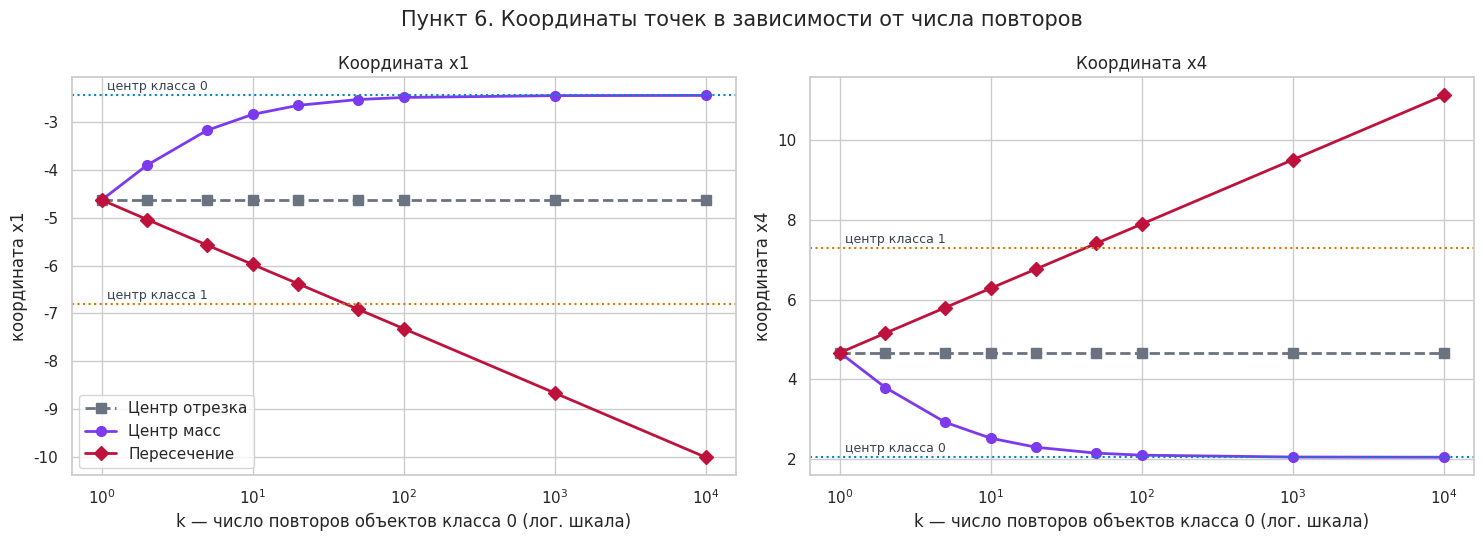

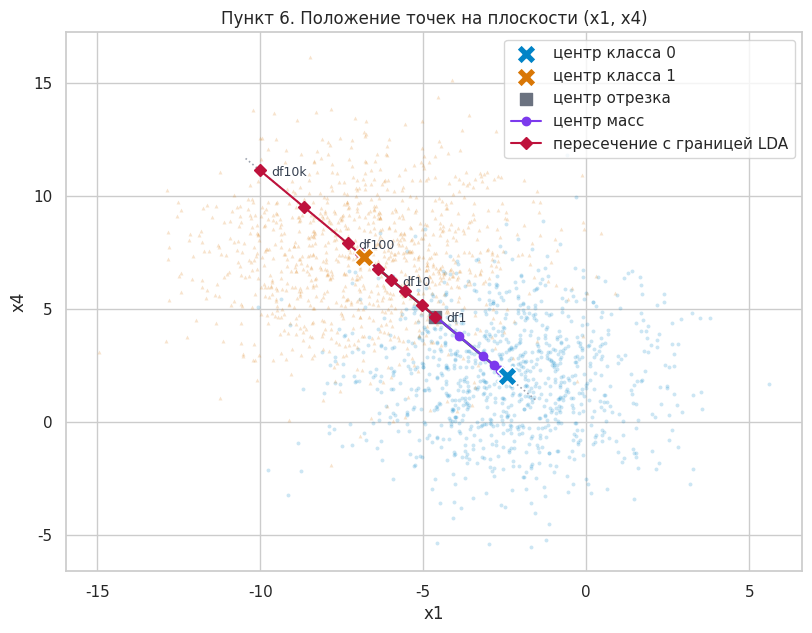

In [14]:
POINT_STYLE = {
    "Центр отрезка": dict(color="#6b7280", linestyle="--", marker="s"),
    "Центр масс": dict(color="#7c3aed", linestyle="-", marker="o"),
    "Пересечение": dict(color="#be123c", linestyle="-", marker="D"),
}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, axis in zip(axes, ["x1", "x4"]):
    for label, style in POINT_STYLE.items():
        ax.plot(points["k"], points[f"{label} {axis}"], linewidth=2, markersize=7, label=label, **style)
    for cls in (REPEATED, OTHER):
        value = MU[cls][PAIR.index(axis)]
        ax.axhline(value, color=CLASS_COLORS[cls], linestyle=":", linewidth=1.5)
        ax.annotate(f"центр класса {cls}", (1, value), xytext=(4, 4), textcoords="offset points",
                    color="#374151", fontsize=9)
    ax.set(xscale="log", xlabel="k — число повторов объектов класса 0 (лог. шкала)",
           ylabel=f"координата {axis}", title=f"Координата {axis}")
axes[0].legend(loc="best")
fig.suptitle("Пункт 6. Координаты точек в зависимости от числа повторов", fontsize=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 7))
for cls in (REPEATED, OTHER):
    part = X1[y1 == cls]
    ax.scatter(part[:, 0], part[:, 1], s=8, c=CLASS_COLORS[cls], marker=CLASS_MARKERS[cls], alpha=0.2, linewidths=0)
t_line = np.linspace(-0.2, max(1.2, points["t пересечения"].max() + 0.1), 2)
ax.plot(*(MU[REPEATED][:, None] + segment[:, None] * t_line), color="#9ca3af", linestyle=":", linewidth=1.2)
ax.plot(*np.c_[MU[REPEATED], MU[OTHER]], color="#4b5563", linewidth=2)
for cls in (REPEATED, OTHER):
    ax.scatter(*MU[cls], s=200, c=CLASS_COLORS[cls], marker="X", edgecolors="white", linewidths=1.2, zorder=8,
               label=f"центр класса {cls}")
ax.scatter(*midpoint, s=70, label="центр отрезка", zorder=6, **{k: v for k, v in POINT_STYLE["Центр отрезка"].items() if k != "linestyle"})
ax.plot(points["Центр масс x1"], points["Центр масс x4"], markersize=6, label="центр масс", zorder=6, **POINT_STYLE["Центр масс"])
ax.plot(points["Пересечение x1"], points["Пересечение x4"], markersize=6, label="пересечение с границей LDA", zorder=6, **POINT_STYLE["Пересечение"])
for _, row in points[points["Датасет"].isin(["df1", "df10", "df100", "df10k"])].iterrows():
    ax.annotate(row["Датасет"], (row["Пересечение x1"], row["Пересечение x4"]), xytext=(8, -4),
                textcoords="offset points", fontsize=9, color="#374151")
ax.set(xlabel="x1", ylabel="x4", title="Пункт 6. Положение точек на плоскости (x1, x4)")
ax.legend(loc="best")
plt.show()

**Что видно.**

- Центр отрезка не зависит от k: средние классов при повторе не меняются, точка (−4.63, 4.67), t = 0.5.
- Общий центр масс движется к центру повторяемого класса 0: t = 1/(k + 1). Уже на df100 он практически совпадает с центром класса 0: (−2.48, 2.09) против (−2.44, 2.04).
- На df1 пересечение с границей LDA совпадает с центром отрезка: при равных априорных вероятностях LDA проводит границу ровно посередине (в метрике Σ). С ростом k точка пересечения движется в противоположную сторону — к классу 1: t = 0.59 (df2), 0.81 (df10), 0.90 (df20). Между df20 и df50 она проходит центр класса 1 и дальше лежит на продолжении отрезка; для df10k t = 1.73, точка (−10.01, 11.13).
- Рост t почти линеен по ln k: t ≈ 0.5 + ln k / Δ², где Δ ≈ 2.7 — расстояние Махаланобиса между центрами. Поэтому на логарифмической шкале линии почти прямые.

## [7] ROC, PR и PR-gain: целевой класс 1

Целевой (положительный) класс — 1. Его объекты не повторяются, поэтому с ростом k он становится всё более редким. Оцениваем решающую функцию LDA из пункта [4] на всех строках соответствующего датасета, то есть на тех же данных, на которых строилась граница. Оценка на отложенных данных — в пункте [9].

- **ROC**: TPR = TP/(TP+FN) против FPR = FP/(FP+TN). AUROC — площадь под кривой.
- **PR**: precision = TP/(TP+FP) против recall = TPR. AUPRC считаем как average precision (`average_precision_score`); для сравнения приводим и площадь по трапециям.
- **PR-gain** ([Flach & Kull, 2015](https://papers.nips.cc/paper/5867-precision-recall-gain-curves-pr-analysis-done-right)). Пусть π — доля положительных. Тогда
  precision gain = (precision − π) / ((1 − π)·precision), recall gain = (recall − π) / ((1 − π)·recall).
  Кривую берём на участке recall gain ∈ [0, 1], AUPRGC — площадь под ней. AUPRGC = 1 у идеальной модели и около 0 у модели не лучше случайной: у неё precision ≈ π на всех порогах, и precision gain ≈ 0.
  Диагональ из (0, 1) в (1, 0) — **линия тестов нулевой эффективности**. В её точках F1 такой же, как у правила «всё — целевой класс»; само это правило — точка (1, 0). Линии равного F1 в PR-gain-пространстве прямые: F1-gain = (precision gain + recall gain) / 2.

В sklearn PR-gain нет, поэтому функция написана ниже. Сначала проверяем её на крайних случаях.

In [15]:
def prg_curve(is_positive, score):
    """Кривая PR-gain и площадь под ней (Flach & Kull, 2015).

    Возвращает recall gain, precision gain и AUPRGC. Точка recall gain = 0 (recall = π)
    находится линейной интерполяцией TP и FP между соседними порогами, как в авторской реализации.
    """
    order = np.argsort(-score, kind="mergesort")
    score, is_positive = score[order], is_positive[order]
    last = np.r_[np.flatnonzero(np.diff(score)), len(score) - 1]   # последний объект каждого порога
    tp = np.r_[0.0, np.cumsum(is_positive)[last]]
    fp = np.r_[0.0, last + 1 - tp[1:]]
    pos, neg = tp[-1], fp[-1]
    pi = pos / (pos + neg)
    i = np.searchsorted(tp, pi * pos)                               # первый порог с recall ≥ π
    alpha = (pi * pos - tp[i - 1]) / (tp[i] - tp[i - 1])
    tp = np.r_[pi * pos, tp[i:]]
    fp = np.r_[fp[i - 1] + alpha * (fp[i] - fp[i - 1]), fp[i:]]
    precision, recall = tp / (tp + fp), tp / pos
    recall_gain = (recall - pi) / ((1 - pi) * recall)
    precision_gain = (precision - pi) / ((1 - pi) * precision)
    return recall_gain, precision_gain, auc(recall_gain, precision_gain)


check_labels = np.r_[np.ones(30), np.zeros(70)].astype(bool)
print("Идеальное ранжирование:", prg_curve(check_labels, np.r_[np.ones(30), np.zeros(70)])[2])
print("Константная оценка:", prg_curve(check_labels, np.zeros(100))[2])
print("Случайная оценка (среднее по 200 повторам):",
      round(np.mean([prg_curve(check_labels, np.random.default_rng(s).random(100))[2] for s in range(200)]), 3))

Идеальное ранжирование: 1.0
Константная оценка: 0.0
Случайная оценка (среднее по 200 повторам): 0.01


Идеальное ранжирование даёт 1, константа — 0. У случайной оценки площадь в среднем около нуля (0.01): precision случайной модели колеблется вокруг π, поэтому precision gain колеблется вокруг нуля.

**Пункт 7. Целевой класс 1**

,Датасет,k,Строк,Доля целевого класса π,AUROC,AUPRC (AP),AUPRC (трапеции),AUPRGC
0,df1,1,2000,0.5,0.9716,0.9731,0.9731,0.9588
1,df2,2,3000,0.3333,0.9715,0.9522,0.9522,0.9784
2,df5,5,6000,0.1667,0.9715,0.9064,0.9064,0.9913
3,df10,10,11000,0.09091,0.9715,0.8554,0.8553,0.9957
4,df20,20,21000,0.04762,0.9715,0.7902,0.7902,0.9978
5,df50,50,51000,0.01961,0.9715,0.6896,0.6895,0.9991
6,df100,100,101000,0.009901,0.9715,0.6128,0.6127,0.9996
7,df1000,1000,1001000,0.000999,0.9715,0.4547,0.4547,1
8,df10k,10000,10001000,9.999e-05,0.9715,0.423,0.423,1


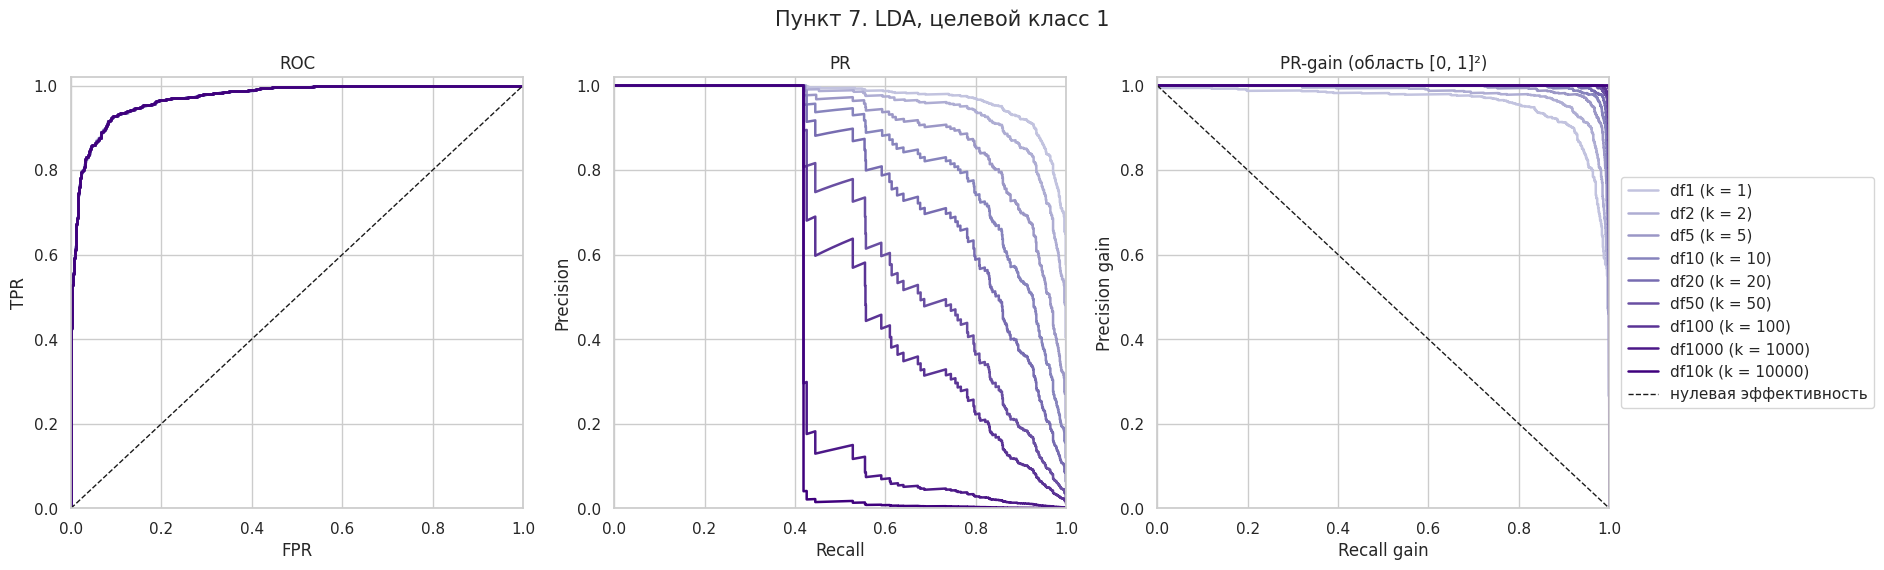

In [16]:
def evaluate_lda(target):
    """ROC, PR и PR-gain для решающей функции LDA на каждом датасете; target — целевой класс."""
    rows, curves = [], {}
    for name, k in REPEATS.items():
        X, y, _ = pair_data[name]
        f = lda_models[name].decision_function(X)
        score = f if target == OTHER else -f
        positive = y == target
        fpr, tpr, _ = roc_curve(positive, score)
        precision, recall, _ = precision_recall_curve(positive, score)
        recall_gain, precision_gain, auprg = prg_curve(positive, score)
        curves[name] = dict(fpr=fpr, tpr=tpr, precision=precision, recall=recall,
                            recall_gain=recall_gain, precision_gain=precision_gain)
        rows.append({
            "Датасет": name, "k": k, "Строк": len(y), "Доля целевого класса π": positive.mean(),
            "AUROC": roc_auc_score(positive, score), "AUPRC (AP)": average_precision_score(positive, score),
            "AUPRC (трапеции)": auc(recall, precision), "AUPRGC": auprg,
        })
    return pd.DataFrame(rows), curves


def plot_curves(curves, target, item):
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
    for name, c in curves.items():
        style = dict(color=K_COLORS[name], linewidth=1.8, label=f"{name} (k = {REPEATS[name]})")
        axes[0].plot(c["fpr"], c["tpr"], **style)
        axes[1].plot(c["recall"], c["precision"], **style)
        axes[2].plot(c["recall_gain"], c["precision_gain"], **style)
    axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[2].plot([0, 1], [1, 0], "k--", linewidth=1, label="нулевая эффективность")
    axes[0].set(xlabel="FPR", ylabel="TPR", title="ROC")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="PR")
    axes[2].set(xlabel="Recall gain", ylabel="Precision gain", title="PR-gain (область [0, 1]²)")
    for ax in axes:
        ax.set(xlim=(0, 1), ylim=(0, 1.02))
    axes[2].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.suptitle(f"Пункт {item}. LDA, целевой класс {target}", fontsize=15)
    fig.tight_layout()
    plt.show()


metrics_1, curves_1 = evaluate_lda(target=OTHER)
show(metrics_1, "Пункт 7. Целевой класс 1")
plot_curves(curves_1, target=OTHER, item=7)

**Что видно.**

- **AUROC одинаков на всех датасетах: 0.9715** (0.9716 на df1), ROC-кривые совпадают. TPR и FPR — доли внутри своих классов, а копии увеличивают числитель и знаменатель FPR в одно и то же число раз. Направление w почти не меняется, значит, не меняется и порядок объектов.
- **AUPRC падает: 0.973 → 0.613 (df100) → 0.423 (df10k).** Precision = TP/(TP+FP), а каждый объект класса 0, ошибочно оказавшийся выше порога, приносит k ложных срабатываний.
- На всех PR-кривых precision равна 1 до recall ≈ 0.42. Это объекты класса 1, которые LDA оценила выше всех объектов класса 0: над ними нет ни одного ложного срабатывания при любом k. Дальше precision при больших k обрушивается, и на df10k AUPRC почти равен этой доле.
- **AUPRGC растёт: 0.959 → 1.000.** PR-gain сравнивает precision с базовым уровнем π. Когда класс 1 составляет 0.01 % строк, даже precision 0.01 в сто раз выше случайной, и precision gain близок к 1. AUPRC и AUPRGC отвечают на разные вопросы: «насколько чистый результат» и «насколько он лучше случайного».

## [8] Другой целевой класс: класс 0

Теперь положительный класс — 0, тот, чьи объекты повторяются. Оценка для него — `−f(x)`: чем меньше f, тем увереннее модель в классе 0. Решения те же, что в пунктах [4] и [7].

**Пункт 8. Целевой класс 0**

,Датасет,k,Строк,Доля целевого класса π,AUROC,AUPRC (AP),AUPRC (трапеции),AUPRGC
0,df1,1,2000,0.5,0.9716,0.9716,0.9715,0.9562
1,df2,2,3000,0.6667,0.9715,0.9849,0.9848,0.926
2,df5,5,6000,0.8333,0.9715,0.9937,0.9937,0.8699
3,df10,10,11000,0.9091,0.9715,0.9968,0.9968,0.8083
4,df20,20,21000,0.9524,0.9715,0.9984,0.9984,0.7349
5,df50,50,51000,0.9804,0.9715,0.9993,0.9993,0.6133
6,df100,100,101000,0.9901,0.9715,0.9997,0.9997,0.5274
7,df1000,1000,1001000,0.999,0.9715,1,1,0.4187
8,df10k,10000,10001000,0.9999,0.9715,1,1,0.419


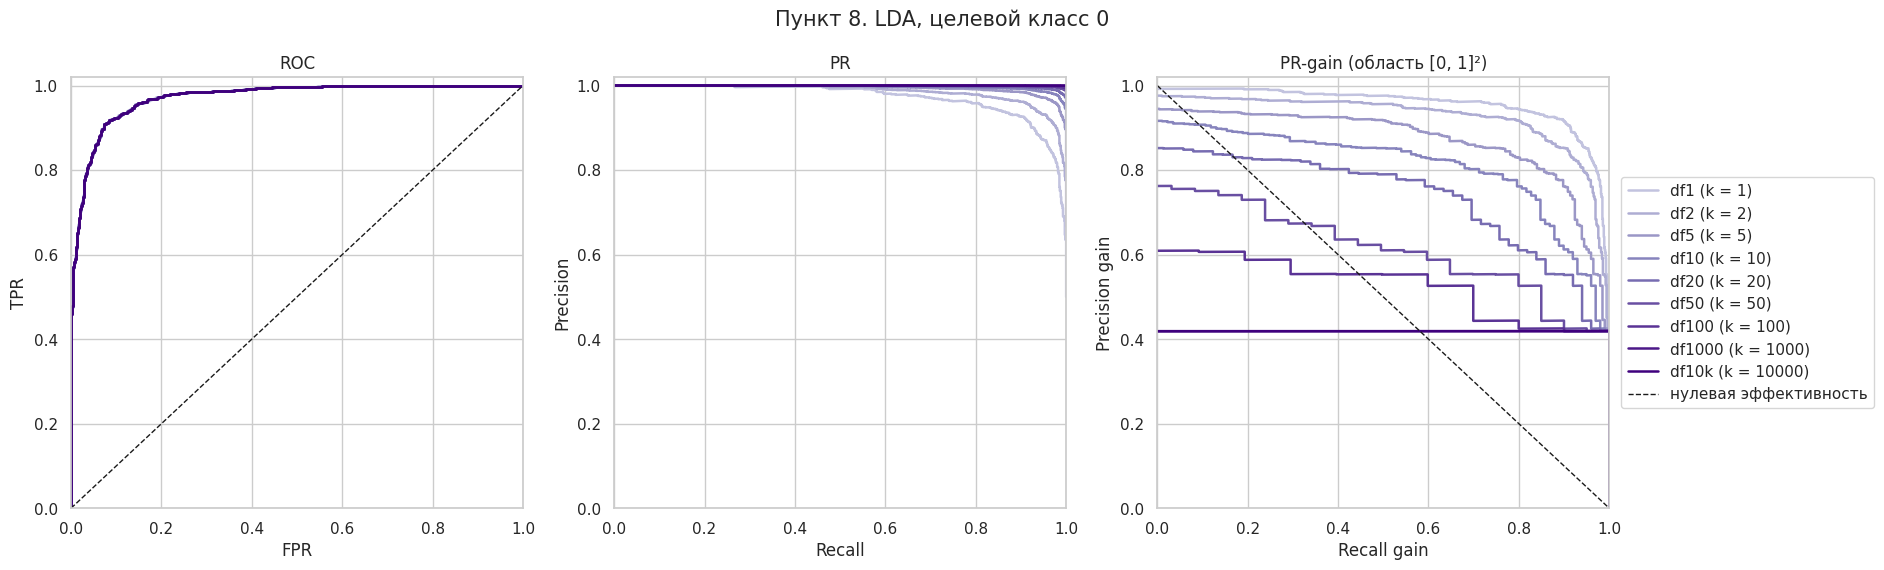

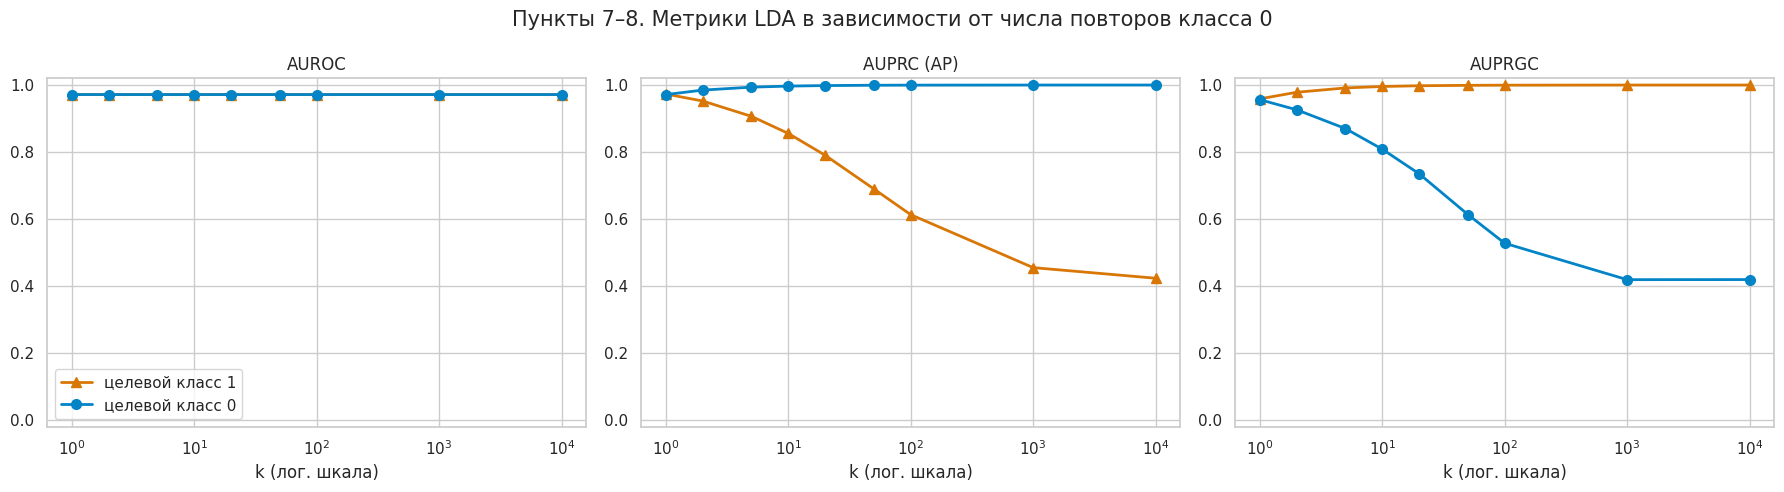

In [17]:
metrics_0, curves_0 = evaluate_lda(target=REPEATED)
show(metrics_0, "Пункт 8. Целевой класс 0")
plot_curves(curves_0, target=REPEATED, item=8)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["AUROC", "AUPRC (AP)", "AUPRGC"]):
    for target, table, color, marker in [(OTHER, metrics_1, CLASS_COLORS[OTHER], "^"),
                                         (REPEATED, metrics_0, CLASS_COLORS[REPEATED], "o")]:
        ax.plot(table["k"], table[metric], color=color, marker=marker, linewidth=2, markersize=7,
                label=f"целевой класс {target}")
    ax.set(xscale="log", xlabel="k (лог. шкала)", title=metric, ylim=(-0.02, 1.02))
axes[0].legend(loc="lower left")
fig.suptitle("Пункты 7–8. Метрики LDA в зависимости от числа повторов класса 0", fontsize=15)
fig.tight_layout()
plt.show()

**Что видно.**

- **AUROC тот же — 0.9715.** Смена целевого класса заменяет f на −f и отражает ROC-кривую; площадь не меняется.
- **AUPRC растёт до 1.000.** Когда целевой класс — 99.99 % строк, даже случайная оценка даёт precision ≈ 0.9999. Высокий AUPRC здесь почти ничего не говорит о модели, его нужно сравнивать с π.
- **AUPRGC падает с 0.956 до 0.419.** PR-gain рассматривает только recall ∈ [π, 1]: для df10k это последние 0.01 % строк класса 0 — хвост ранжирования, где класс 0 перемешан с классом 1. При k ≥ 1000 этот хвост целиком состоит из копий одного объекта класса 0 с самой низкой оценкой, поэтому кривые df1000 и df10k почти горизонтальны и совпадают.
- Итог пунктов [7]–[8]: AUROC не зависит ни от дисбаланса, ни от выбора целевого класса; AUPRC зависит от обоих; AUPRGC нормирует результат к базовому уровню и меняется противоположно AUPRC.

## [9] Кросс-валидация на df10k: AUROC и AUPRC с доверительными интервалами

В df10k у каждого объекта класса 0 есть 10 000 копий. Если делить на фолды строки, копии одного объекта попадут и в обучение, и в контроль — это утечка. Поэтому фолды строим по исходным объектам (`obj_id`, со стратификацией по классу), и все копии объекта уходят в одну часть. Модель — LDA из пункта [4], обучается на копиях.

Для каждого числа фолдов n ∈ {3, 5, 10, 20, 50, 100}:

- на каждом фолде строим ROC и PR на контрольной части;
- кривые интерполируем на общую сетку (FPR для ROC, recall для PR) и усредняем по фолдам;
- 95 %-й доверительный интервал среднего (CI95) равен mean ± t₀.₉₇₅, ₙ₋₁ · s / √n, где s — стандартное отклонение по фолдам.

ROC строим для целевого класса 1; для класса 0 AUROC тот же. PR строим для обоих целевых классов, потому что AUPRC зависит от этого выбора. Интервал приблизительный: обучающие части разных фолдов пересекаются, поэтому оценки фолдов не независимы.

In [18]:
FOLDS = [3, 5, 10, 20, 50, 100]
GRID = np.linspace(0, 1, 201)

X10, y10, ids10 = pair_data["df10k"]
position = np.full(len(df1), -1)
position[ids1] = np.arange(len(ids1))
row_object = position[ids10]                      # номер уникального объекта для каждой строки df10k

cv = {}
start_all = time.perf_counter()
for n_splits in FOLDS:
    start = time.perf_counter()
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    result = {key: [] for key in ["auroc", "auprc_1", "auprc_0", "share_1", "tpr", "precision_1", "precision_0"]}
    for train_objects, _ in folds.split(np.zeros(len(y1)), y1):
        in_train = np.zeros(len(y1), dtype=bool)
        in_train[train_objects] = True
        train_rows = in_train[row_object]
        model = LinearDiscriminantAnalysis(solver="lsqr").fit(X10[train_rows], y10[train_rows])
        y_test = y10[~train_rows]
        f = model.decision_function(X10[~train_rows])
        fpr, tpr, _ = roc_curve(y_test == OTHER, f)
        result["auroc"].append(auc(fpr, tpr))
        result["tpr"].append(np.r_[0.0, np.interp(GRID[1:], fpr, tpr)])
        result["share_1"].append(np.mean(f[y_test == OTHER] > f[y_test == REPEATED].max()))
        for target, score in [(OTHER, f), (REPEATED, -f)]:
            precision, recall, _ = precision_recall_curve(y_test == target, score)
            result[f"auprc_{target}"].append(average_precision_score(y_test == target, score))
            result[f"precision_{target}"].append(np.interp(GRID, recall[::-1], precision[::-1]))
    cv[n_splits] = {key: np.array(value) for key, value in result.items()}
    print(f"{n_splits:>3} фолдов: {time.perf_counter() - start:5.1f} с")
print(f"Всего: {time.perf_counter() - start_all:.0f} с")

  3 фолдов:   3.6 с


  5 фолдов:   5.1 с


 10 фолдов:   9.0 с


 20 фолдов:  16.7 с


 50 фолдов:  41.4 с


100 фолдов:  80.1 с
Всего: 156 с


In [19]:
def mean_ci(values, axis=0):
    """Среднее и 95%-й доверительный интервал среднего по t-распределению."""
    n = values.shape[axis]
    mean = values.mean(axis=axis)
    half = stats.t.ppf(0.975, n - 1) * values.std(axis=axis, ddof=1) / np.sqrt(n)
    return mean, mean - half, mean + half


rows = []
for n_splits, r in cv.items():
    row = {"Фолдов": n_splits, "Объектов каждого класса в контроле": round(N_PER_CLASS / n_splits)}
    for key, label, digits in [("auroc", "AUROC", 4), ("auprc_1", "AUPRC, класс 1", 4), ("auprc_0", "AUPRC, класс 0", 7)]:
        mean, low, high = mean_ci(r[key])
        row[f"{label}: среднее"] = f"{mean:.{digits}f}"
        row[f"{label}: CI95"] = f"[{low:.{digits}f}; {high:.{digits}f}]"
        row[f"{label}: s"] = r[key].std(ddof=1)
    row["Доля класса 1 выше всех объектов класса 0"] = r["share_1"].mean()
    rows.append(row)
cv_table = pd.DataFrame(rows)
show(cv_table, "Пункт 9. LDA на df10k: метрики по фолдам")

**Пункт 9. LDA на df10k: метрики по фолдам**

,Фолдов,Объектов каждого класса в контроле,AUROC: среднее,AUROC: CI95,AUROC: s,"AUPRC, класс 1: среднее","AUPRC, класс 1: CI95","AUPRC, класс 1: s","AUPRC, класс 0: среднее","AUPRC, класс 0: CI95","AUPRC, класс 0: s",Доля класса 1 выше всех объектов класса 0
0,3,333,0.9711,[0.9565; 0.9857],0.00587,0.4579,[0.2995; 0.6162],0.06373,0.9999967,[0.9999949; 0.9999985],7.376e-07,0.455
1,5,200,0.9715,[0.9606; 0.9823],0.008718,0.4844,[0.3701; 0.5987],0.09205,0.9999967,[0.9999954; 0.9999980],1.035e-06,0.482
2,10,100,0.9712,[0.9644; 0.9781],0.009587,0.5794,[0.4613; 0.6975],0.1651,0.9999967,[0.9999959; 0.9999975],1.073e-06,0.578
3,20,50,0.9717,[0.9666; 0.9768],0.01084,0.6637,[0.5875; 0.7399],0.1628,0.9999968,[0.9999962; 0.9999974],1.285e-06,0.663
4,50,20,0.9723,[0.9665; 0.9781],0.02043,0.7732,[0.7202; 0.8263],0.1867,0.9999969,[0.9999962; 0.9999976],2.335e-06,0.773
5,100,10,0.9729,[0.9665; 0.9793],0.03233,0.8551,[0.8209; 0.8893],0.1725,0.9999970,[0.9999962; 0.9999977],3.705e-06,0.855


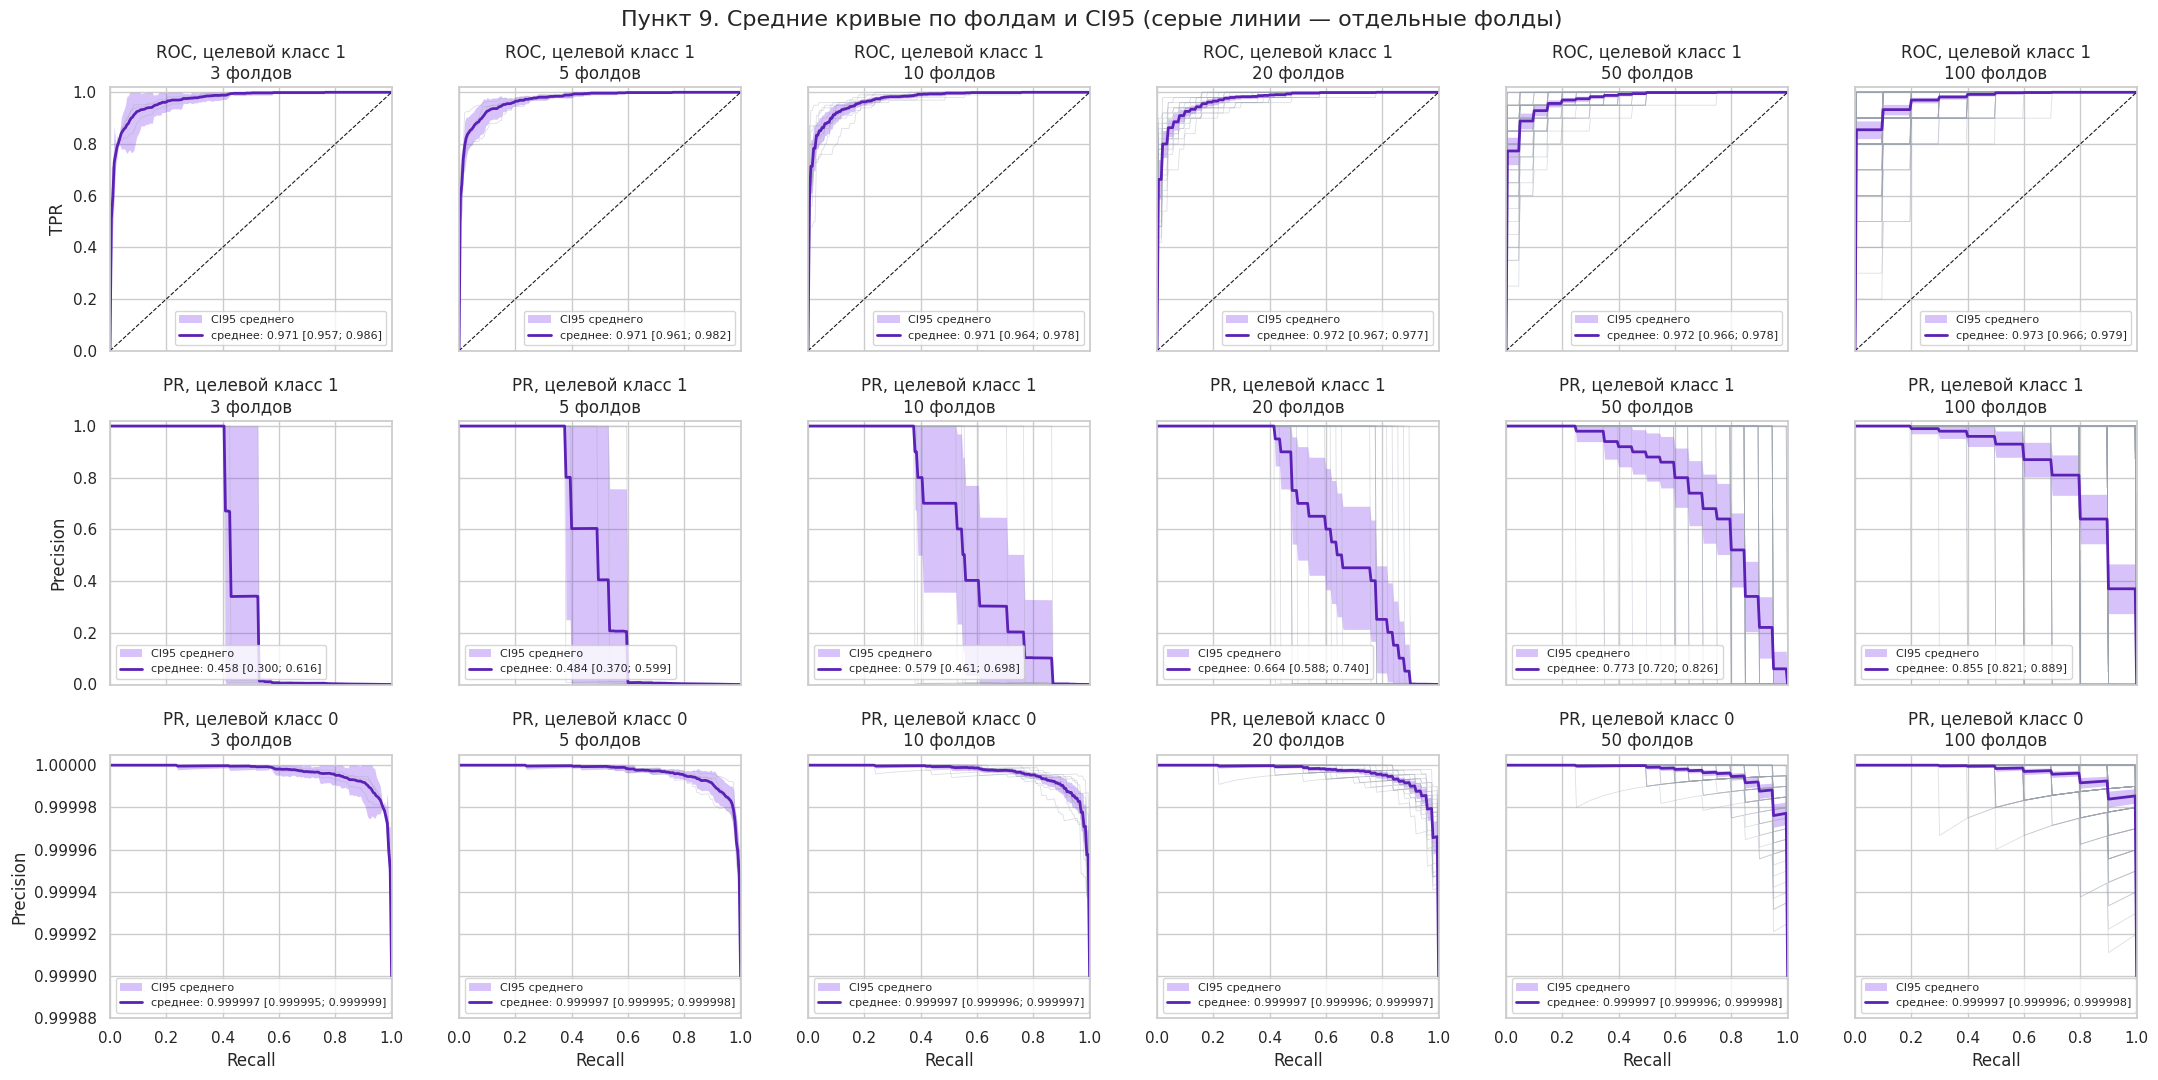

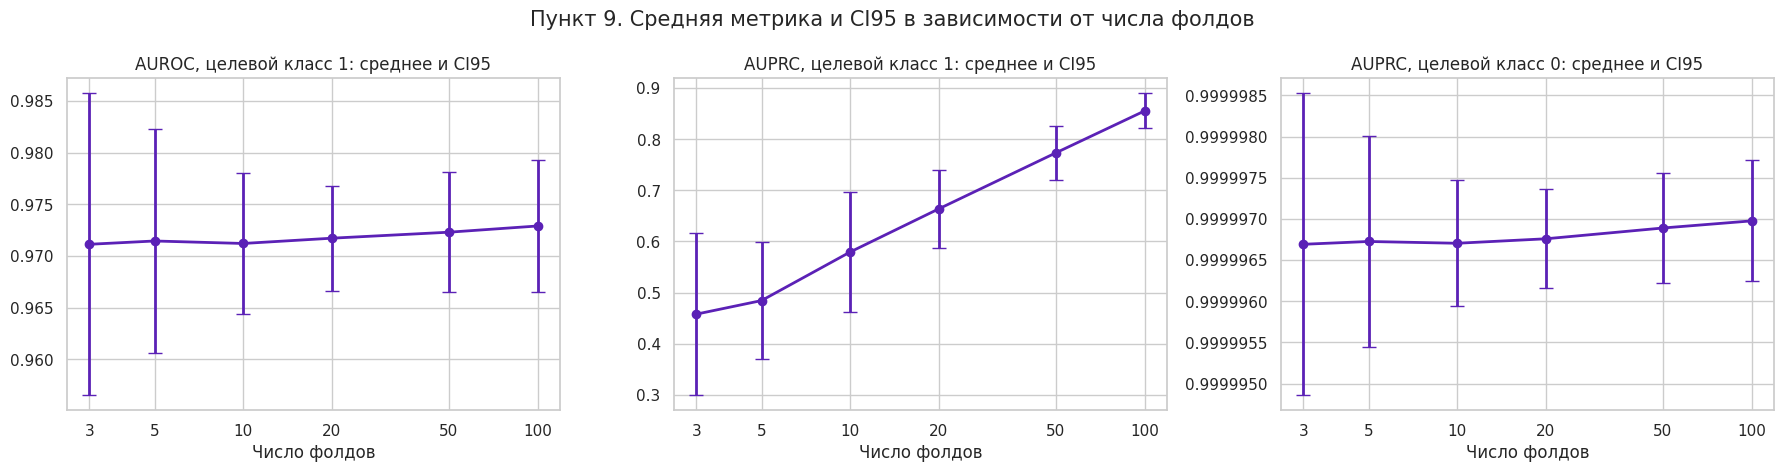

In [20]:
panels = [
    ("tpr", "auroc", "ROC, целевой класс 1", "FPR", "TPR"),
    ("precision_1", "auprc_1", "PR, целевой класс 1", "Recall", "Precision"),
    ("precision_0", "auprc_0", "PR, целевой класс 0", "Recall", "Precision"),
]
fig, axes = plt.subplots(len(panels), len(FOLDS), figsize=(22, 11), sharex=True, sharey="row")
for col, n_splits in enumerate(FOLDS):
    r = cv[n_splits]
    for row, (curve_key, metric_key, title, xlabel, ylabel) in enumerate(panels):
        ax = axes[row, col]
        for curve in r[curve_key]:
            ax.plot(GRID, curve, color="#9ca3af", linewidth=0.6, alpha=0.35)
        mean, low, high = mean_ci(r[curve_key])
        auc_mean, auc_low, auc_high = mean_ci(r[metric_key])
        ax.fill_between(GRID, np.clip(low, 0, 1), np.clip(high, 0, 1), color="#7c3aed", alpha=0.3, linewidth=0,
                        label="CI95 среднего")
        ax.plot(GRID, mean, color="#5b21b6", linewidth=2,
                label=f"среднее: {auc_mean:.{6 if metric_key == 'auprc_0' else 3}f} "
                      f"[{auc_low:.{6 if metric_key == 'auprc_0' else 3}f}; {auc_high:.{6 if metric_key == 'auprc_0' else 3}f}]")
        if curve_key == "tpr":
            ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
        ax.set(xlim=(0, 1), ylim=(0.99988, 1.000005) if curve_key == "precision_0" else (0, 1.02),
               title=f"{title}\n{n_splits} фолдов")
        ax.ticklabel_format(axis="y", useOffset=False, style="plain")
        ax.legend(loc="lower left" if curve_key != "tpr" else "lower right", fontsize=8)
        if row == len(panels) - 1:
            ax.set_xlabel(xlabel)
        if col == 0:
            ax.set_ylabel(ylabel)
fig.suptitle("Пункт 9. Средние кривые по фолдам и CI95 (серые линии — отдельные фолды)", fontsize=16)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (_, metric_key, title, _, _) in zip(axes, panels):
    stats_by_fold = np.array([mean_ci(cv[n][metric_key]) for n in FOLDS])
    ax.errorbar(FOLDS, stats_by_fold[:, 0], yerr=[stats_by_fold[:, 0] - stats_by_fold[:, 1], stats_by_fold[:, 2] - stats_by_fold[:, 0]],
                color="#5b21b6", marker="o", capsize=5, linewidth=2)
    ax.set(xscale="log", xticks=FOLDS, xticklabels=FOLDS, xlabel="Число фолдов",
           title=title.replace("ROC", "AUROC").replace("PR,", "AUPRC,") + ": среднее и CI95")
    ax.minorticks_off()
    ax.ticklabel_format(axis="y", useOffset=False, style="plain")
fig.suptitle("Пункт 9. Средняя метрика и CI95 в зависимости от числа фолдов", fontsize=15)
fig.tight_layout()
plt.show()

**Что видно.**

- **AUROC устойчив: среднее 0.971–0.973 при любом числе фолдов.** Разброс между фолдами растёт (s от 0.006 до 0.032), потому что контрольные части уменьшаются с 333 до 10 объектов каждого класса. Но CI95 среднего в целом сужается: его ширина 0.029 при 3 фолдах и 0.012–0.013 при 50–100. При 3 фолдах интервал широкий ещё и из-за квантиля t с двумя степенями свободы (4.30 вместо ≈ 2).
- **AUPRC для класса 1 растёт с числом фолдов: 0.458 → 0.855.** Модель от этого не лучше — это свойство метрики при дисбалансе 10 000 : 1. Один объект класса 0 над объектом класса 1 приносит сразу 10 000 ложных срабатываний. Поэтому AP почти равен доле объектов класса 1, оценённых выше всех объектов класса 0 контрольной части (последний столбец таблицы почти совпадает со средним AUPRC: расхождение не больше 0.003). Чем меньше объектов класса 0 в контроле, тем менее экстремален их максимум и тем больше эта доля. Интервалы для 3 и 100 фолдов не пересекаются: [0.300; 0.616] и [0.821; 0.889]. Сравнивать AUPRC можно только при одинаковой схеме разбиения.
- **AUPRC для класса 0 насыщен:** около 0.999997 при любом числе фолдов, различия — в шестом знаке. Для частого класса метрика неинформативна.

## Вывод

1. Повтор объектов не добавляет информации о форме классов, но меняет веса. LDA сохраняет направление решающей функции и сдвигает свободный член примерно на −ln k. Граница уходит к редкому классу и начиная с df50 проходит дальше его центра. Recall редкого класса падает с 0.92 до 0.02, а accuracy растёт до 0.9999 и перестаёт что-либо значить.
2. Линейный SVM на дубликатах эквивалентен SVM с весами объектов. Он реагирует на дисбаланс сильнее LDA, а при k ≥ 1000 вырождается в константу «всё — класс 0».
3. С ростом k общий центр масс движется к повторяемому классу, точка пересечения границы с отрезком — в противоположную сторону, центр отрезка неподвижен.
4. AUROC не зависит ни от дисбаланса, ни от выбора целевого класса (0.9715 во всех случаях). AUPRC сильно зависит от обоих: для редкого класса падает до 0.42, для частого растёт до 1. AUPRGC нормирует precision к базовому уровню π и меняется противоположно AUPRC.
5. При кросс-валидации на данных с копиями фолды нужно строить по исходным объектам, иначе копии попадут и в обучение, и в контроль. AUROC устойчив к числу фолдов. AUPRC редкого класса при сильном дисбалансе зависит от размера контрольной части, поэтому значения при разном числе фолдов несравнимы.